In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:

# Load image in grayscale
img = cv2.imread('Mn.jpg', 0)

# Get image dimensions
M, N = img.shape

# Apply FFT
F = np.fft.fft2(img)

# Shift zero frequency to center
Fshift = np.fft.fftshift(F)

# Calculate distance from center
u = np.arange(M)
v = np.arange(N)
U, V = np.meshgrid(v, u)

D = np.sqrt((V - M/2)**2 + (U - N/2)**2)

# Cutoff frequency
D0 = 50

Ideal Low-Pass Filter

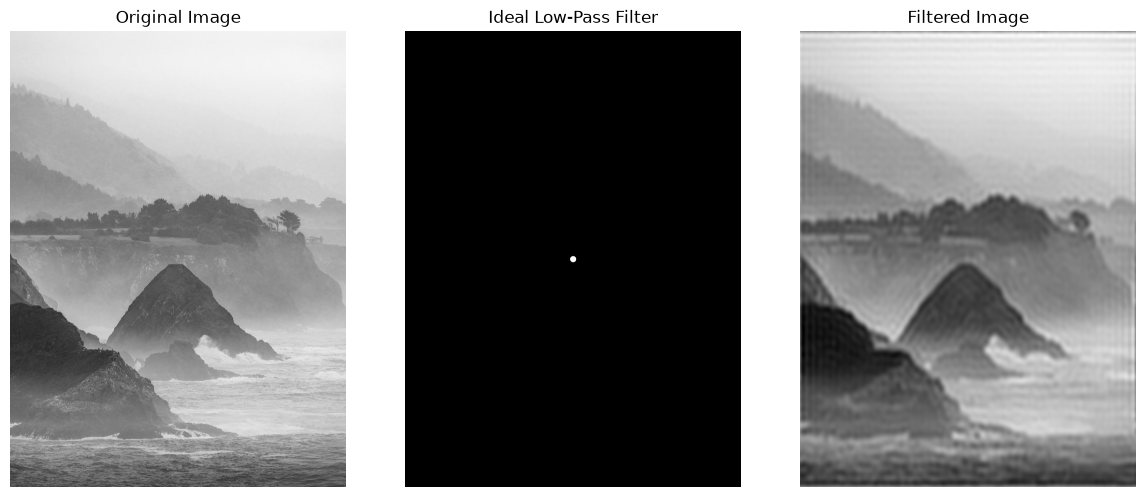

In [3]:

# Create Ideal Low-Pass Filter
H = np.zeros((M, N), dtype=np.float32)
H[D <= D0] = 1

# Apply filter
Gshift = Fshift * H

# Inverse FFT
G = np.fft.ifftshift(Gshift)
filtered = np.fft.ifft2(G)

# Get absolute pixel values
filtered = np.abs(filtered)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(H, cmap='gray')
plt.title('Ideal Low-Pass Filter')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()


Butterworth Low-Pass Filter

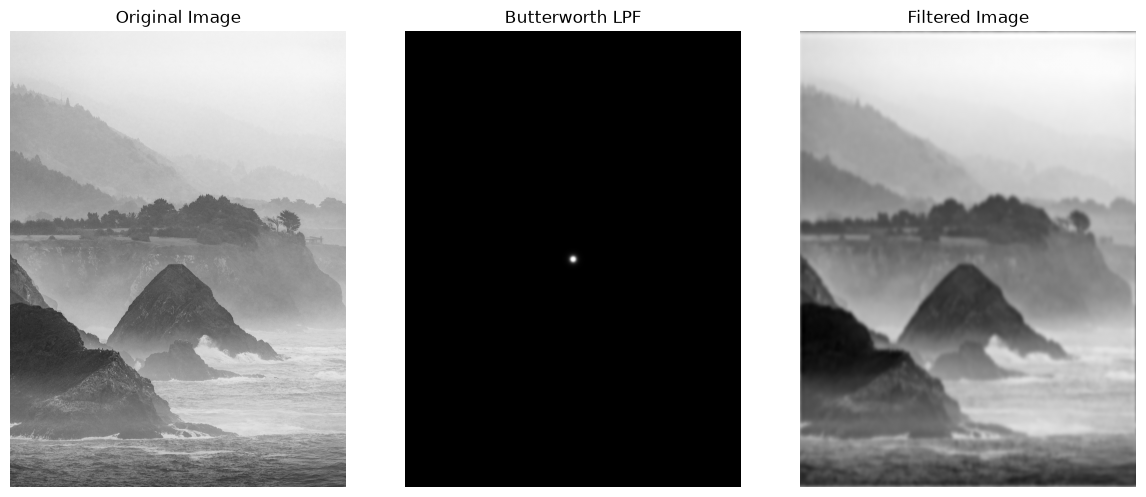

In [4]:
# Set cutoff frequency and order
n = 2

# Create Butterworth Low-Pass Filter
H = 1 / (1 + (D / D0)**(2 * n))

# Apply filter
Gshift = Fshift * H

# Inverse FFT
G = np.fft.ifftshift(Gshift)
filtered = np.fft.ifft2(G)

# Get absolute pixel values
filtered = np.abs(filtered)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(H, cmap='gray')
plt.title('Butterworth LPF')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()


Gaussian Low-Pass Filter

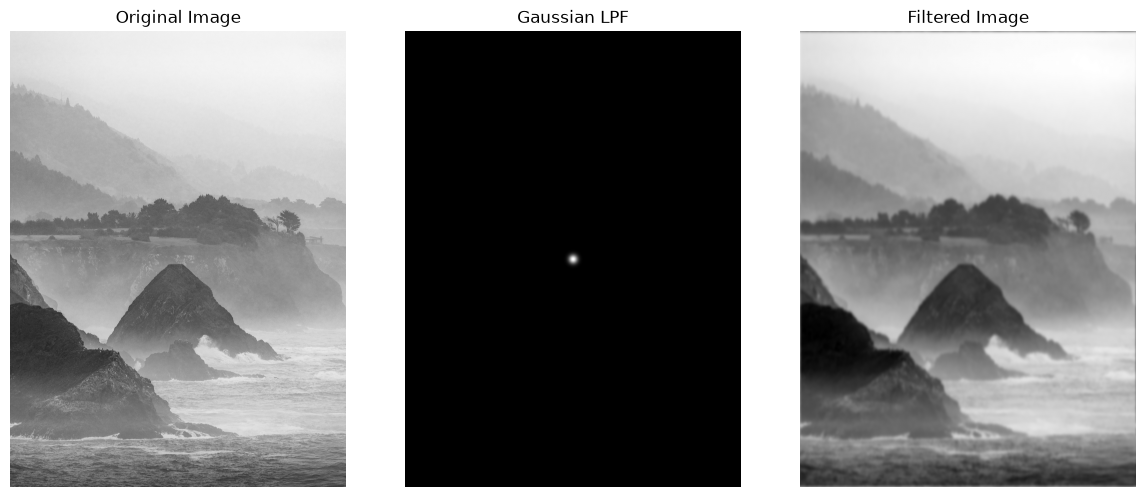

In [5]:
# Create Gaussian Low-Pass Filter
H = np.exp(-(D**2) / (2 * (D0**2)))

# Apply filter
Gshift = Fshift * H

# Inverse FFT
G = np.fft.ifftshift(Gshift)
filtered = np.fft.ifft2(G)

# Get absolute pixel values
filtered = np.abs(filtered)

# Display images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(H, cmap='gray')
plt.title('Gaussian LPF')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap='gray')
plt.title('Filtered Image')
plt.axis('off')

plt.tight_layout()
plt.show()
